# Integrating 28 mouse scRNA-seq samples across 5 tissues and 2 ages

**Data.** 10x Cell Ranger `filtered_feature_bc_matrix.h5` files (mm10), one per
sample, described in `metadata.txt`: five tissues (bone marrow, large
intestine, lung, PBMC, spleen), young (9 weeks) and old (19 months) female SPF
mice. The same mice (ids 1–3, 52–54) were sampled in several tissues.

**What this notebook does**

1. load every sample and attach its metadata;
2. quality control per sample (adaptive MAD thresholds) and doublet removal;
3. normalise, choose highly variable genes across samples, PCA;
4. look at the data **before** integration;
5. integrate with **Harmony**, batch = `sample`;
6. check the integration (sample mixing, marker coherence);
7. cluster, find markers, give clusters provisional broad cell-type labels;
8. cell-type composition by tissue and age;
9. pseudobulk old-vs-young differential expression per tissue × cell type;
10. save the integrated object.

**Two design points to keep in mind**

* Each sample is one mouse at one age, so `sample` is nested inside `age`.
  Correcting for `sample` can also remove part of a real age effect. The
  integrated space is for **clustering and labelling only**; age differences
  in expression are tested on the **raw counts**, summed per mouse
  (pseudobulk), never on the corrected values.
* The replicate for age comparisons is the **mouse** (n = 2–3 per group), not
  the cell. Tests on thousands of cells as if they were independent give
  tiny, meaningless p-values.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scanpy as sc
import anndata as ad

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)

DATA_DIR = Path("data")           # metadata.txt and the <tissue>/<sample>/ folders
OUT_DIR = Path("results/all_tissues")  # everything the notebook writes (not tracked by git)
OUT_DIR.mkdir(parents=True, exist_ok=True)
SEED = 0
DOUBLET_THRESHOLD = 0.25          # scrublet score cut-off (see the doublet section)

sc.settings.verbosity = 1
sc.settings.figdir = OUT_DIR
sc.settings.set_figure_params(dpi=80, frameon=False, figsize=(4.5, 4.5))
np.random.seed(SEED)

## 1. Load samples and metadata

The folder for each sample is `<tissue>/<sample>/filtered_feature_bc_matrix.h5`.
Gene symbols are made unique (a few mm10 symbols repeat); Ensembl ids are kept
in `var['gene_ids']`. Raw counts are stored in `layers['counts']` before any
transformation — the doublet detector and the pseudobulk test need them.

In [2]:
meta = pd.read_csv(DATA_DIR / "metadata.txt", dtype=str)
meta["age"] = pd.Categorical(meta["age"], categories=["9w", "19M"])
meta["mouse"] = "m" + meta["mouse_id"]
display(meta.groupby(["tissue", "age"], observed=True).size().unstack())

adatas = {}
for r in meta.itertuples():
    f = DATA_DIR / r.tissue / r.sample / "filtered_feature_bc_matrix.h5"
    a = sc.read_10x_h5(f)
    a.var_names_make_unique()
    for col in ["sample", "tissue", "age", "sex", "mouse"]:
        a.obs[col] = getattr(r, col)
    adatas[r.sample] = a

adata = ad.concat(adatas, label="sample_check", index_unique="-", merge="same")
assert (adata.obs["sample"] == adata.obs["sample_check"]).all()
del adata.obs["sample_check"]
for col in ["sample", "tissue", "mouse"]:
    adata.obs[col] = adata.obs[col].astype("category")
adata.obs["age"] = pd.Categorical(adata.obs["age"], categories=["9w", "19M"])
adata.obs["tissue_age"] = (adata.obs["tissue"].astype(str) + "_" + adata.obs["age"].astype(str)).astype("category")
adata.layers["counts"] = adata.X.copy()
adata

age,9w,19M
tissue,,
BoneMarrow,3,3
LargeI,3,3
lung,3,3
pbmc,3,2
spleen,3,2


AnnData object with n_obs × n_vars = 46463 × 32285
    obs: 'sample', 'tissue', 'age', 'sex', 'mouse', 'tissue_age'
    var: 'gene_ids', 'feature_types', 'genome'
    layers: 'counts'

## 2. Quality control

Per-cell metrics: total counts, genes detected, and the share of counts in
mitochondrial (`mt-`), ribosomal (`Rps`/`Rpl`) and haemoglobin (`Hba`/`Hbb`)
genes.

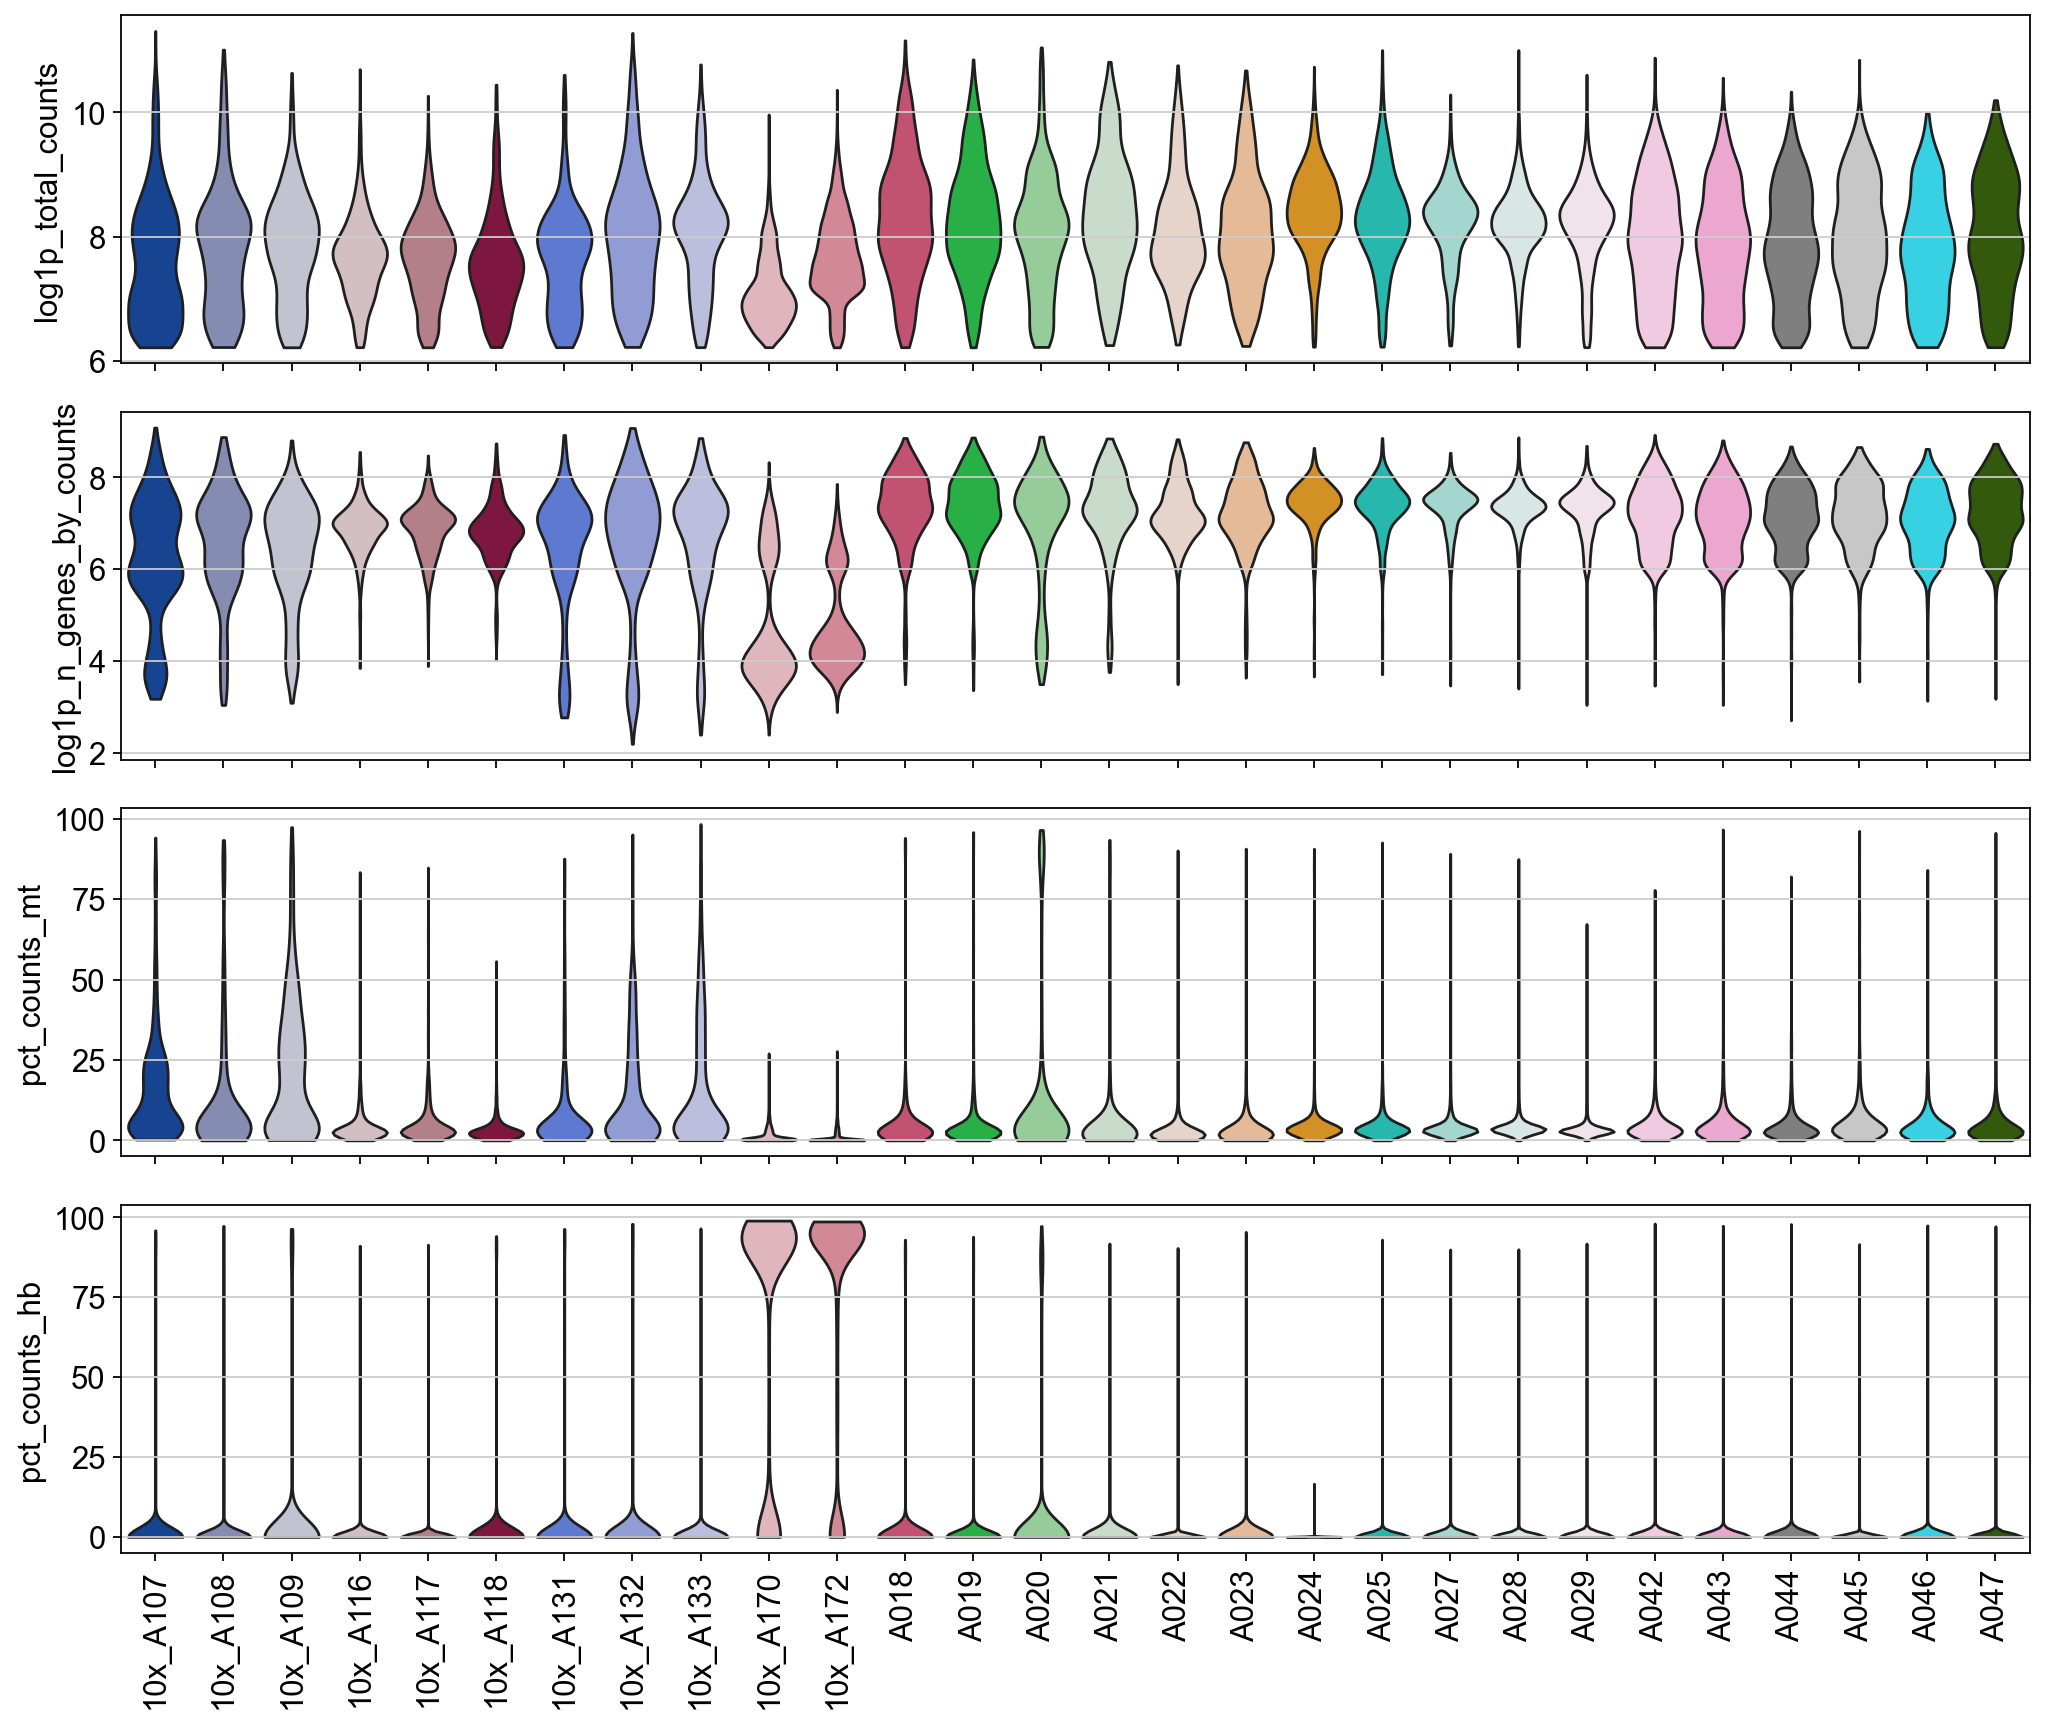

,total_counts,n_genes_by_counts,pct_counts_mt,n_cells
sample,,,,
10x_A107,1823.0,517.0,9.700000,1267
10x_A108,2566.0,910.5,4.900000,698
10x_A109,2676.0,748.0,17.200001,965
10x_A116,2113.0,1036.0,2.700000,951
10x_A117,2191.5,1072.5,3.000000,858
10x_A118,1804.0,916.5,2.400000,1122
10x_A131,2260.0,962.0,3.300000,817
10x_A132,2938.0,979.0,5.700000,831
10x_A133,3342.5,1077.0,6.400000,1056


In [3]:
adata.var["mt"] = adata.var_names.str.startswith("mt-")
adata.var["ribo"] = adata.var_names.str.match(r"^Rp[sl]\d")
adata.var["hb"] = adata.var_names.str.match(r"^Hb[ab]-")
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt", "ribo", "hb"], inplace=True, percent_top=[20], log1p=True)

fig, axes = plt.subplots(4, 1, figsize=(13, 11), sharex=True)
for ax, key in zip(axes, ["log1p_total_counts", "log1p_n_genes_by_counts", "pct_counts_mt", "pct_counts_hb"]):
    sc.pl.violin(adata, key, groupby="sample", rotation=90, stripplot=False, ax=ax, show=False)
    ax.set_xlabel("")
plt.tight_layout(); plt.show()

display(adata.obs.groupby("sample", observed=True)[["total_counts", "n_genes_by_counts", "pct_counts_mt"]]
        .median().round(1).join(adata.obs["sample"].value_counts().rename("n_cells")))

**Filtering rule.** Fixed cut-offs do not fit five tissues at once, so
outliers are called **within each sample**: more than 5 median absolute
deviations (MAD) from the sample median on log counts, log genes or the
top-20-gene share, or more than 5 MADs above the median mitochondrial share.
On top of that:

* **mitochondrial ceiling** 25 %, but 50 % for large intestine — intestinal
  epithelium normally has a high mitochondrial share (A109's median is 17 %),
  and a 25 % cap would remove ~40 % of its cells;
* **at least 200 genes** per cell;
* **red blood cells**: more than 50 % haemoglobin reads *and* fewer than 500
  genes. Erythroid precursors in bone marrow and spleen also express
  haemoglobin but detect many more genes, so they are kept.

**Old PBMC samples A170 and A172 are almost entirely red blood cells**
(~90 % of reads from Hbb-bs, Hbb-bt, Hba-a1/2; median ~70 genes per cell) —
most likely red cells were not lysed before loading. Almost nothing is left
after QC, so these samples are dropped (any sample with fewer than
`MIN_CELLS_PER_SAMPLE` cells left is) and **PBMC has young samples only**:
no PBMC age comparison is possible from this data.

In [4]:
def mad_outlier(x, nmads, side="both"):
    med = np.median(x)
    mad = np.median(np.abs(x - med)) * 1.4826
    if side == "upper":
        return x > med + nmads * mad
    return (x < med - nmads * mad) | (x > med + nmads * mad)

MT_CAP = {"LargeI": 50}           # % mitochondrial reads; 25 for every other tissue
MIN_CELLS_PER_SAMPLE = 100

o = adata.obs
outlier = pd.Series(False, index=adata.obs_names)
for s, idx in o.groupby("sample", observed=True).groups.items():
    x = o.loc[idx]
    bad = (mad_outlier(x["log1p_total_counts"], 5) | mad_outlier(x["log1p_n_genes_by_counts"], 5)
           | mad_outlier(x["pct_counts_in_top_20_genes"], 5) | mad_outlier(x["pct_counts_mt"], 5, "upper"))
    outlier.loc[idx] = bad.to_numpy()
mt_cap = o["tissue"].astype(str).map(MT_CAP).fillna(25).to_numpy()
reasons = pd.DataFrame({
    "red blood cell": (o["pct_counts_hb"] > 50) & (o["n_genes_by_counts"] < 500),
    "MAD outlier": outlier,
    "high mito": o["pct_counts_mt"] > mt_cap,
    "< 200 genes": o["n_genes_by_counts"] < 200,
})
adata.obs["qc_fail"] = reasons.any(axis=1)
display(reasons.groupby(o["sample"], observed=True).mean().join(
    adata.obs.groupby("sample", observed=True)["qc_fail"].mean().rename("removed (any)")).round(3).T)

n0 = adata.n_obs
adata = adata[~adata.obs["qc_fail"]].copy()
n = adata.obs["sample"].value_counts()
small = n[n < MIN_CELLS_PER_SAMPLE].index.tolist()
if small:
    print(f"dropping samples with < {MIN_CELLS_PER_SAMPLE} cells after QC: {small}")
    adata = adata[~adata.obs["sample"].isin(small)].copy()
adata.obs["sample"] = adata.obs["sample"].cat.remove_unused_categories()
sc.pp.filter_genes(adata, min_cells=10)
print(f"kept {adata.n_obs} / {n0} cells, {adata.n_vars} genes, {adata.obs['sample'].nunique()} samples")
display(adata.obs.drop_duplicates("sample").groupby(["tissue", "age"], observed=True).size().unstack()
        .rename_axis(columns="samples left"))

sample,10x_A107,10x_A108,10x_A109,10x_A116,10x_A117,10x_A118,10x_A131,10x_A132,10x_A133,10x_A170,...,A025,A027,A028,A029,A042,A043,A044,A045,A046,A047
red blood cell,0.019,0.007,0.060,0.005,0.002,0.020,0.017,0.022,0.009,0.700,...,0.004,0.006,0.004,0.006,0.005,0.005,0.008,0.001,0.004,0.003
MAD outlier,0.031,0.139,0.000,0.099,0.107,0.121,0.286,0.113,0.134,0.316,...,0.110,0.080,0.060,0.061,0.055,0.057,0.070,0.065,0.066,0.059
high mito,0.054,0.067,0.110,0.006,0.012,0.005,0.027,0.043,0.080,0.001,...,0.012,0.005,0.004,0.001,0.017,0.018,0.020,0.026,0.022,0.023
< 200 genes,0.194,0.119,0.172,0.014,0.012,0.021,0.159,0.138,0.121,0.690,...,0.011,0.010,0.007,0.009,0.010,0.010,0.010,0.010,0.012,0.008
removed (any),0.241,0.231,0.251,0.099,0.107,0.121,0.286,0.244,0.241,1.000,...,0.110,0.080,0.060,0.061,0.055,0.057,0.070,0.065,0.066,0.059


dropping samples with < 100 cells after QC: ['10x_A172', '10x_A170']


kept 31193 / 46463 cells, 21937 genes, 26 samples


samples left,9w,19M
tissue,,
BoneMarrow,3.0,3.0
LargeI,3.0,3.0
lung,3.0,3.0
pbmc,3.0,NaN
spleen,3.0,2.0


### Doublets

Scrublet simulates doublets from each sample's own cells and scores how
doublet-like every real cell is. It runs **per sample** on raw counts, since
doublets only form within one 10x channel.

A fixed threshold (`DOUBLET_THRESHOLD`, 0.25) is used instead of scrublet's
automatic one, which needs scikit-image. Look at
the score histograms: a good threshold sits in the dip between the main
mode and the right tail. To get the automatic threshold instead, run
`pip install scikit-image` and set `threshold=None`.

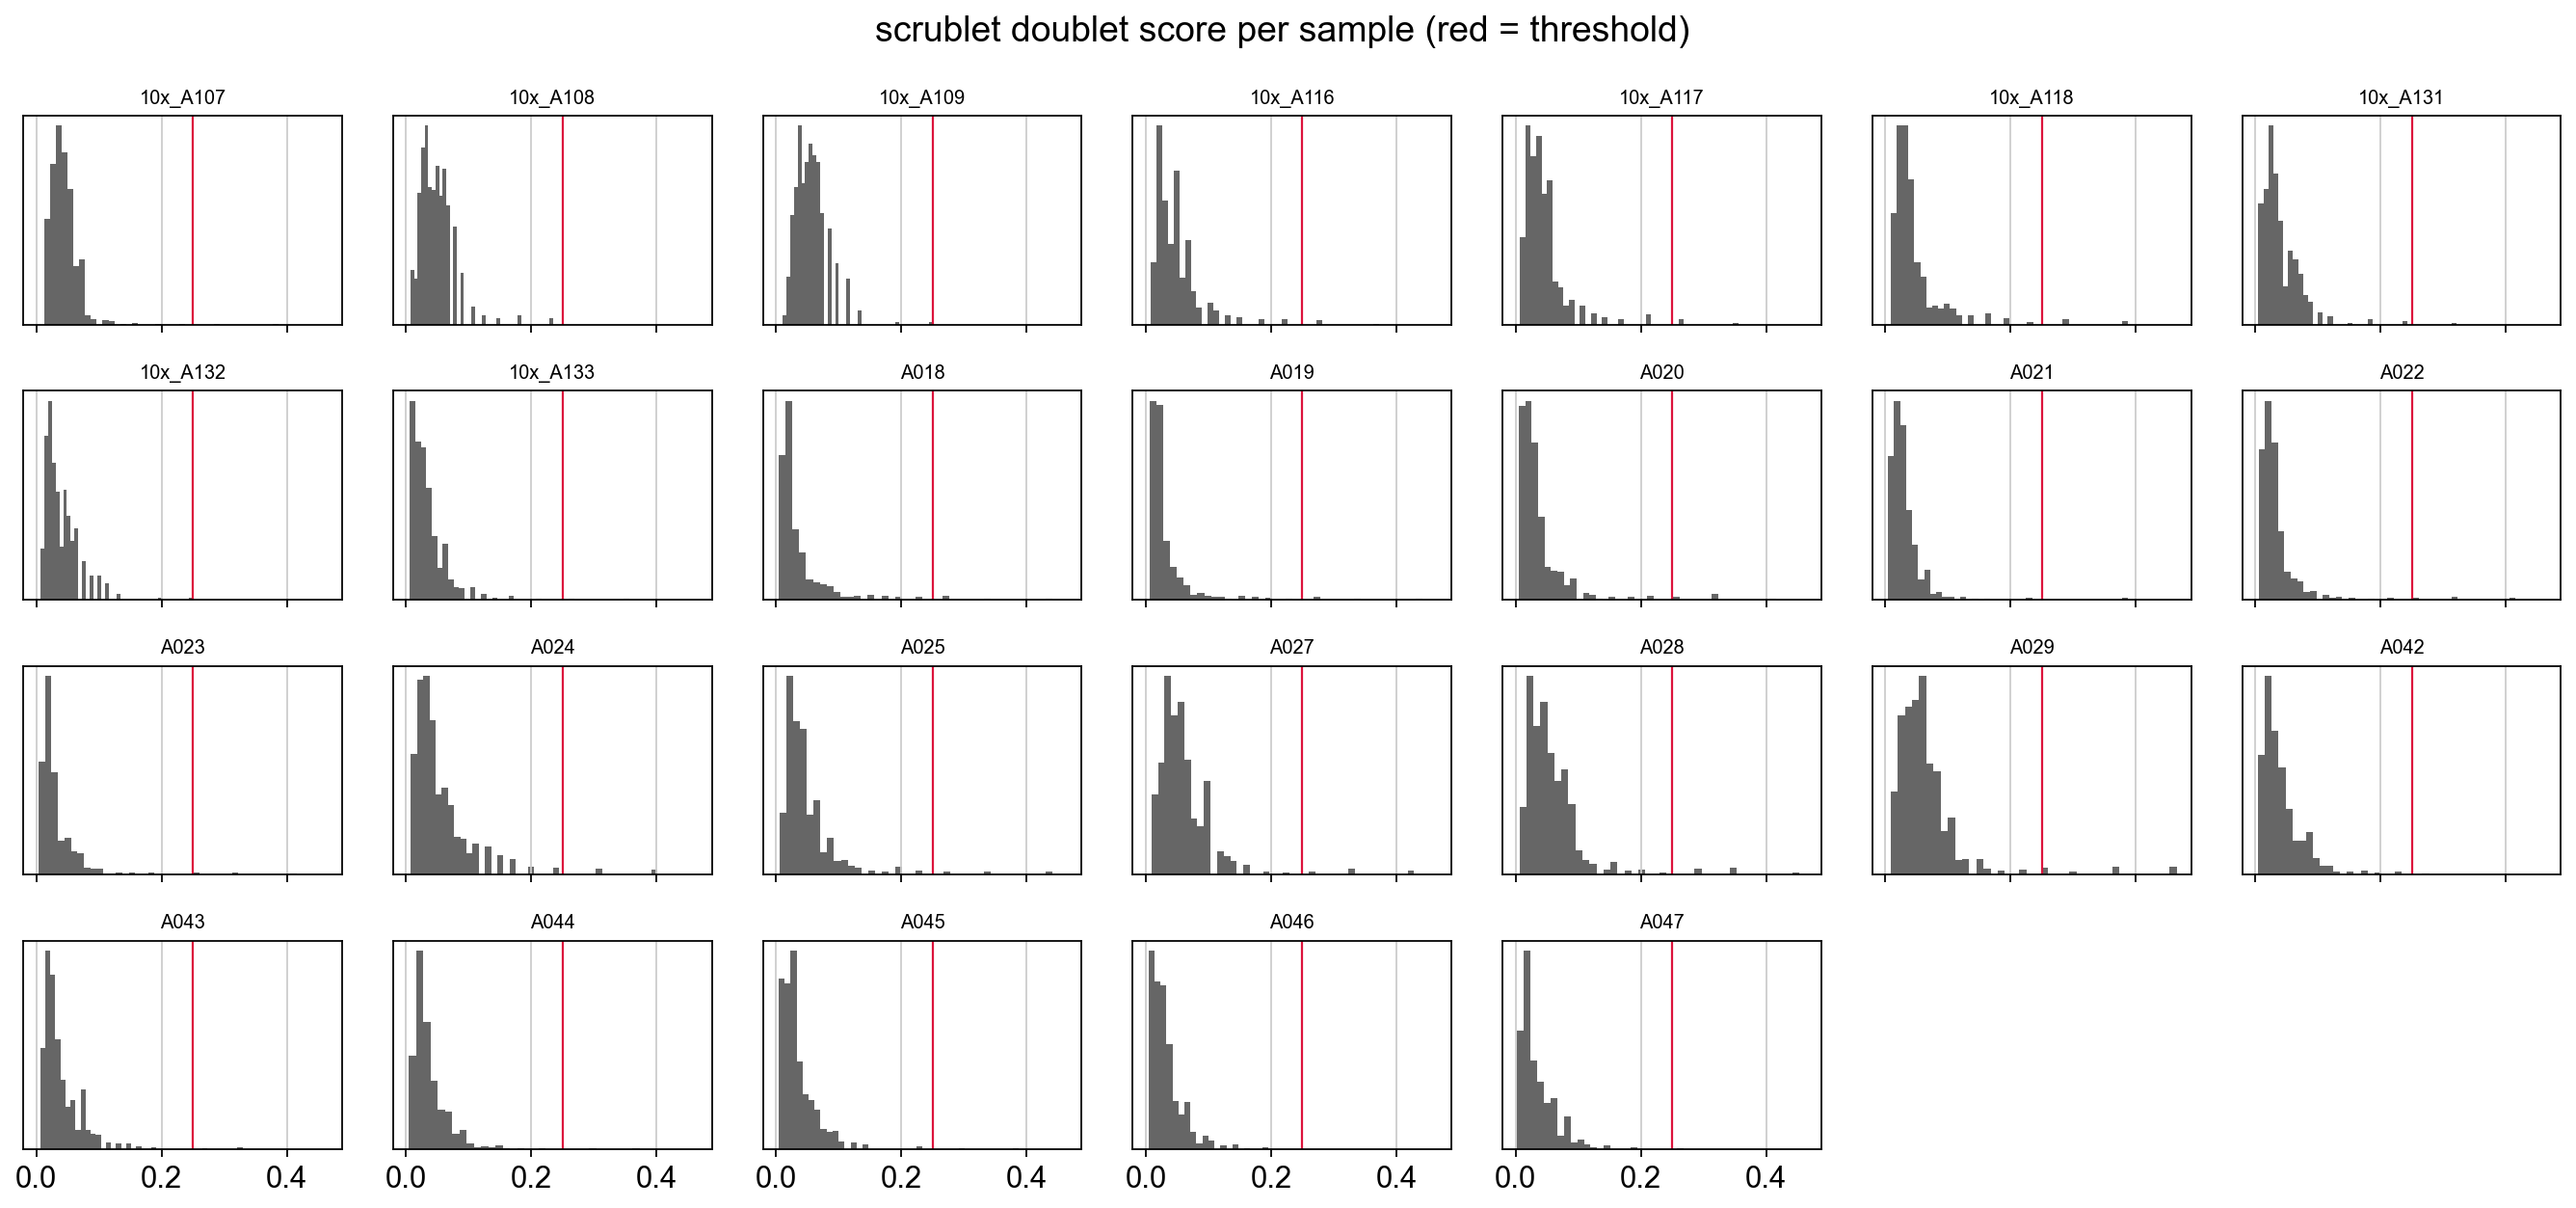

sample,10x_A107,10x_A108,10x_A109,10x_A116,10x_A117,10x_A118,10x_A131,10x_A132,10x_A133,A018,...,A025,A027,A028,A029,A042,A043,A044,A045,A046,A047
called,0.002,0.000,0.001,0.006,0.007,0.010,0.002,0.002,0.002,0.009,...,0.011,0.011,0.014,0.016,0.002,0.003,0.004,0.004,0.001,0.004
"expected (~0.8% per 1,000 cells loaded)",0.008,0.004,0.006,0.007,0.006,0.008,0.005,0.005,0.006,0.013,...,0.012,0.011,0.014,0.015,0.013,0.012,0.015,0.008,0.008,0.011


If 'called' is far below 'expected' (e.g. the large PBMC samples), lower DOUBLET_THRESHOLD and re-run.


30966 cells after doublet removal


In [5]:
scores, calls = [], []
for s in adata.obs["sample"].cat.categories:
    a = sc.AnnData(adata[adata.obs["sample"] == s].layers["counts"].copy(),
                   obs=adata.obs.loc[adata.obs["sample"] == s, []])
    sc.pp.scrublet(a, threshold=DOUBLET_THRESHOLD, random_state=SEED)
    scores.append(a.obs["doublet_score"]); calls.append(a.obs["predicted_doublet"])
adata.obs["doublet_score"] = pd.concat(scores).reindex(adata.obs_names)
adata.obs["predicted_doublet"] = pd.concat(calls).reindex(adata.obs_names).astype(bool)

fig, axes = plt.subplots(4, 7, figsize=(17, 8), sharex=True)
for ax, (s, o) in zip(axes.flat, adata.obs.groupby("sample", observed=True)):
    ax.hist(o["doublet_score"], bins=40, color="0.4")
    ax.axvline(DOUBLET_THRESHOLD, color="crimson", lw=1)
    ax.set_title(s, fontsize=9); ax.set_yticks([])
for ax in axes.flat[adata.obs["sample"].nunique():]:
    ax.axis("off")
plt.suptitle("scrublet doublet score per sample (red = threshold)"); plt.tight_layout(); plt.show()

g = adata.obs.groupby("sample", observed=True)
display(pd.DataFrame({"called": g["predicted_doublet"].mean(),
                      "expected (~0.8% per 1,000 cells loaded)": g.size() / 1000 * 0.008}).round(3).T)
print("If 'called' is far below 'expected' (e.g. the large PBMC samples), lower DOUBLET_THRESHOLD and re-run.")
adata = adata[~adata.obs["predicted_doublet"]].copy()
print(f"{adata.n_obs} cells after doublet removal")

## 3. Normalise, highly variable genes, PCA

* Library-size normalisation to 10,000 counts and `log1p` (stored in `X`;
  raw counts stay in `layers['counts']`).
* 3,000 highly variable genes with the `seurat_v3` method on raw counts,
  chosen **across samples** (`batch_key="sample"`), so a gene that is variable
  in only one sample does not dominate.
* PCA on those genes (50 components).

3000 highly variable genes


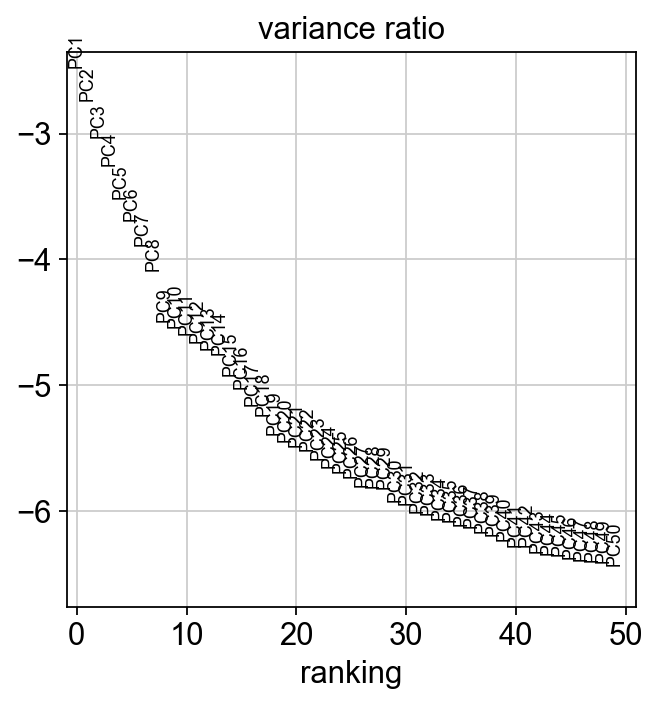

In [6]:
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata.raw = adata    # full log-normalised matrix for marker plots

sc.pp.highly_variable_genes(adata, n_top_genes=3000, flavor="seurat_v3", layer="counts", batch_key="sample")
print(adata.var["highly_variable"].sum(), "highly variable genes")
sc.tl.pca(adata, n_comps=50, mask_var="highly_variable", random_state=SEED)
sc.pl.pca_variance_ratio(adata, n_pcs=50, log=True)

## 4. Before integration

If cells from the same tissue split by sample here, there are sample
(batch) effects to correct. Separation **by tissue** is expected for
tissue-specific cells (epithelium, stroma), but shared immune cell types
(B cells, T cells, neutrophils...) found in several tissues should end up
close together after a good integration.

/Users/terooatt/miniconda3/envs/pbmc-integration/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


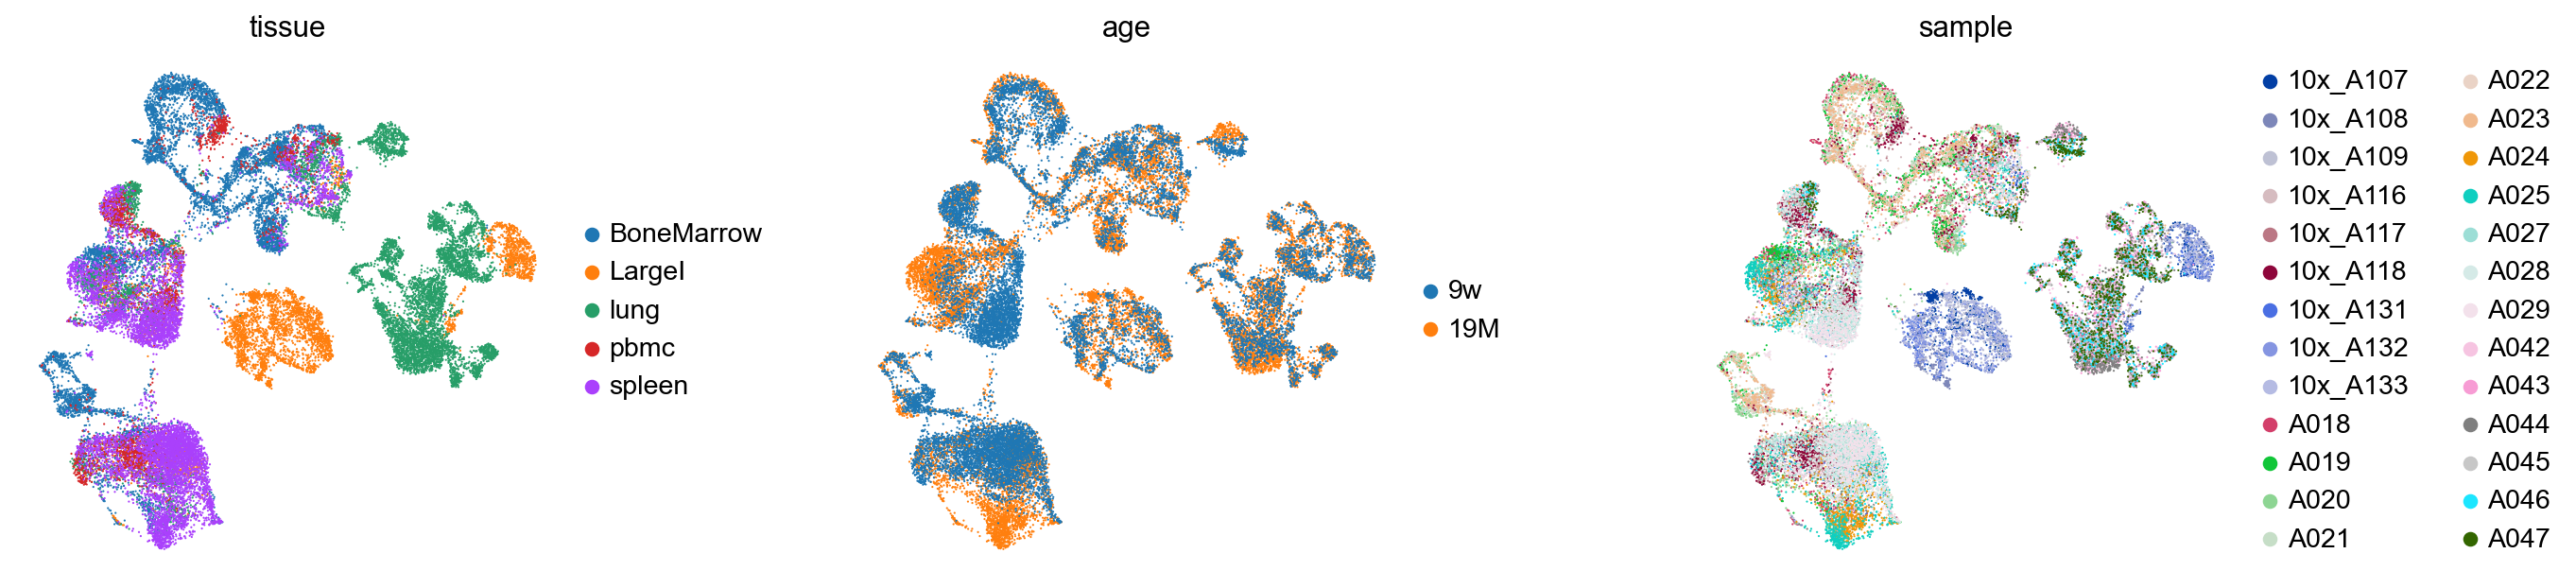

In [7]:
sc.pp.neighbors(adata, use_rep="X_pca", n_pcs=30, random_state=SEED)
sc.tl.umap(adata, random_state=SEED)
adata.obsm["X_umap_unintegrated"] = adata.obsm["X_umap"].copy()
sc.pl.embedding(adata, "X_umap_unintegrated", color=["tissue", "age", "sample"], ncols=3, wspace=0.4)

## 5. Harmony

Harmony moves cells in PCA space so that every cluster contains cells from all
samples in proportion. Fast; corrects the PCs only (no corrected counts).

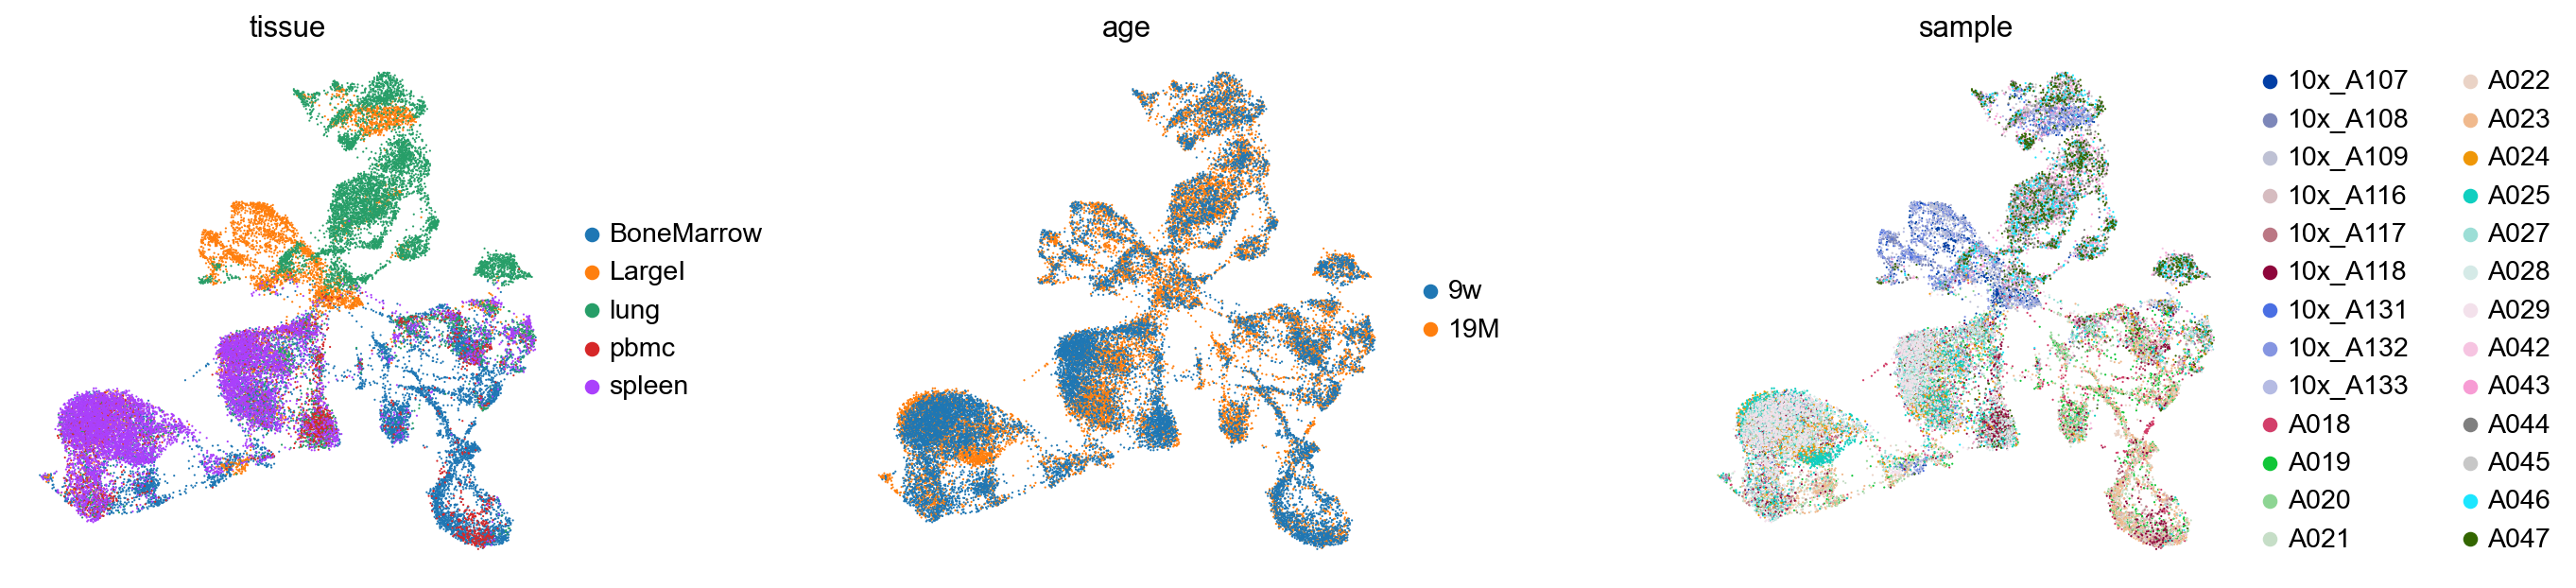

In [8]:
import harmonypy
# called directly: newer harmonypy returns Z_corr in a shape scanpy's wrapper does not expect
ho = harmonypy.run_harmony(adata.obsm["X_pca"], adata.obs, "sample", max_iter_harmony=20,
                           random_state=SEED, verbose=False)
Z = np.asarray(ho.Z_corr)
adata.obsm["X_pca_harmony"] = Z if Z.shape[0] == adata.n_obs else Z.T
sc.pp.neighbors(adata, use_rep="X_pca_harmony", random_state=SEED)
sc.tl.umap(adata, random_state=SEED)
adata.obsm["X_umap_harmony"] = adata.obsm["X_umap"].copy()
sc.pl.embedding(adata, "X_umap_harmony", color=["tissue", "age", "sample"], ncols=3, wspace=0.4)

## 6. Check the integration

Two simple checks, before vs after Harmony:

**Sample mixing.** For every cell, look at its 30 nearest neighbours and
count how many come from **other samples of the same tissue**. Compare with
what random mixing would give (the share of the tissue's cells that are not
in the cell's own sample). A ratio near 1 = samples are well mixed; near 0 =
cells only neighbour their own sample. Only same-tissue neighbours count, so
Harmony does not score well simply by blending tissues together.

**Marker coherence.** Over-correction blurs cell types together. The marker
panels below should stay sharp, compact islands after Harmony. If the mixing
ratio is still low, try a larger `theta` (default 2) in `run_harmony`; if
marker islands blur, lower it.

In [9]:
from sklearn.neighbors import NearestNeighbors

def sample_mixing(rep, k=30):
    X = adata.obsm[rep][:, :30] if rep == "X_pca" else adata.obsm[rep]
    nn = NearestNeighbors(n_neighbors=k + 1).fit(X)
    idx = nn.kneighbors(X, return_distance=False)[:, 1:]
    smp = adata.obs["sample"].cat.codes.to_numpy()
    tis = adata.obs["tissue"].cat.codes.to_numpy()
    same_t = tis[idx] == tis[:, None]
    other_s = same_t & (smp[idx] != smp[:, None])
    observed = other_s.sum(1) / np.maximum(same_t.sum(1), 1)
    n_t = pd.Series(tis).map(pd.Series(tis).value_counts()).to_numpy()
    n_s = pd.Series(smp).map(pd.Series(smp).value_counts()).to_numpy()
    expected = (n_t - n_s) / n_t
    ratio = observed / expected
    return pd.Series(ratio).groupby(adata.obs["tissue"].to_numpy()).median()

mix = pd.DataFrame({name: sample_mixing(rep) for name, rep in
                    [("unintegrated", "X_pca"), ("harmony", "X_pca_harmony")]})
print("median sample-mixing ratio within tissue (1 = random mixing)")
display(mix.round(2))

median sample-mixing ratio within tissue (1 = random mixing)


,unintegrated,harmony
BoneMarrow,0.80,0.91
LargeI,0.89,0.95
lung,0.93,0.99
pbmc,0.85,0.99
spleen,0.80,0.88


X_umap_unintegrated


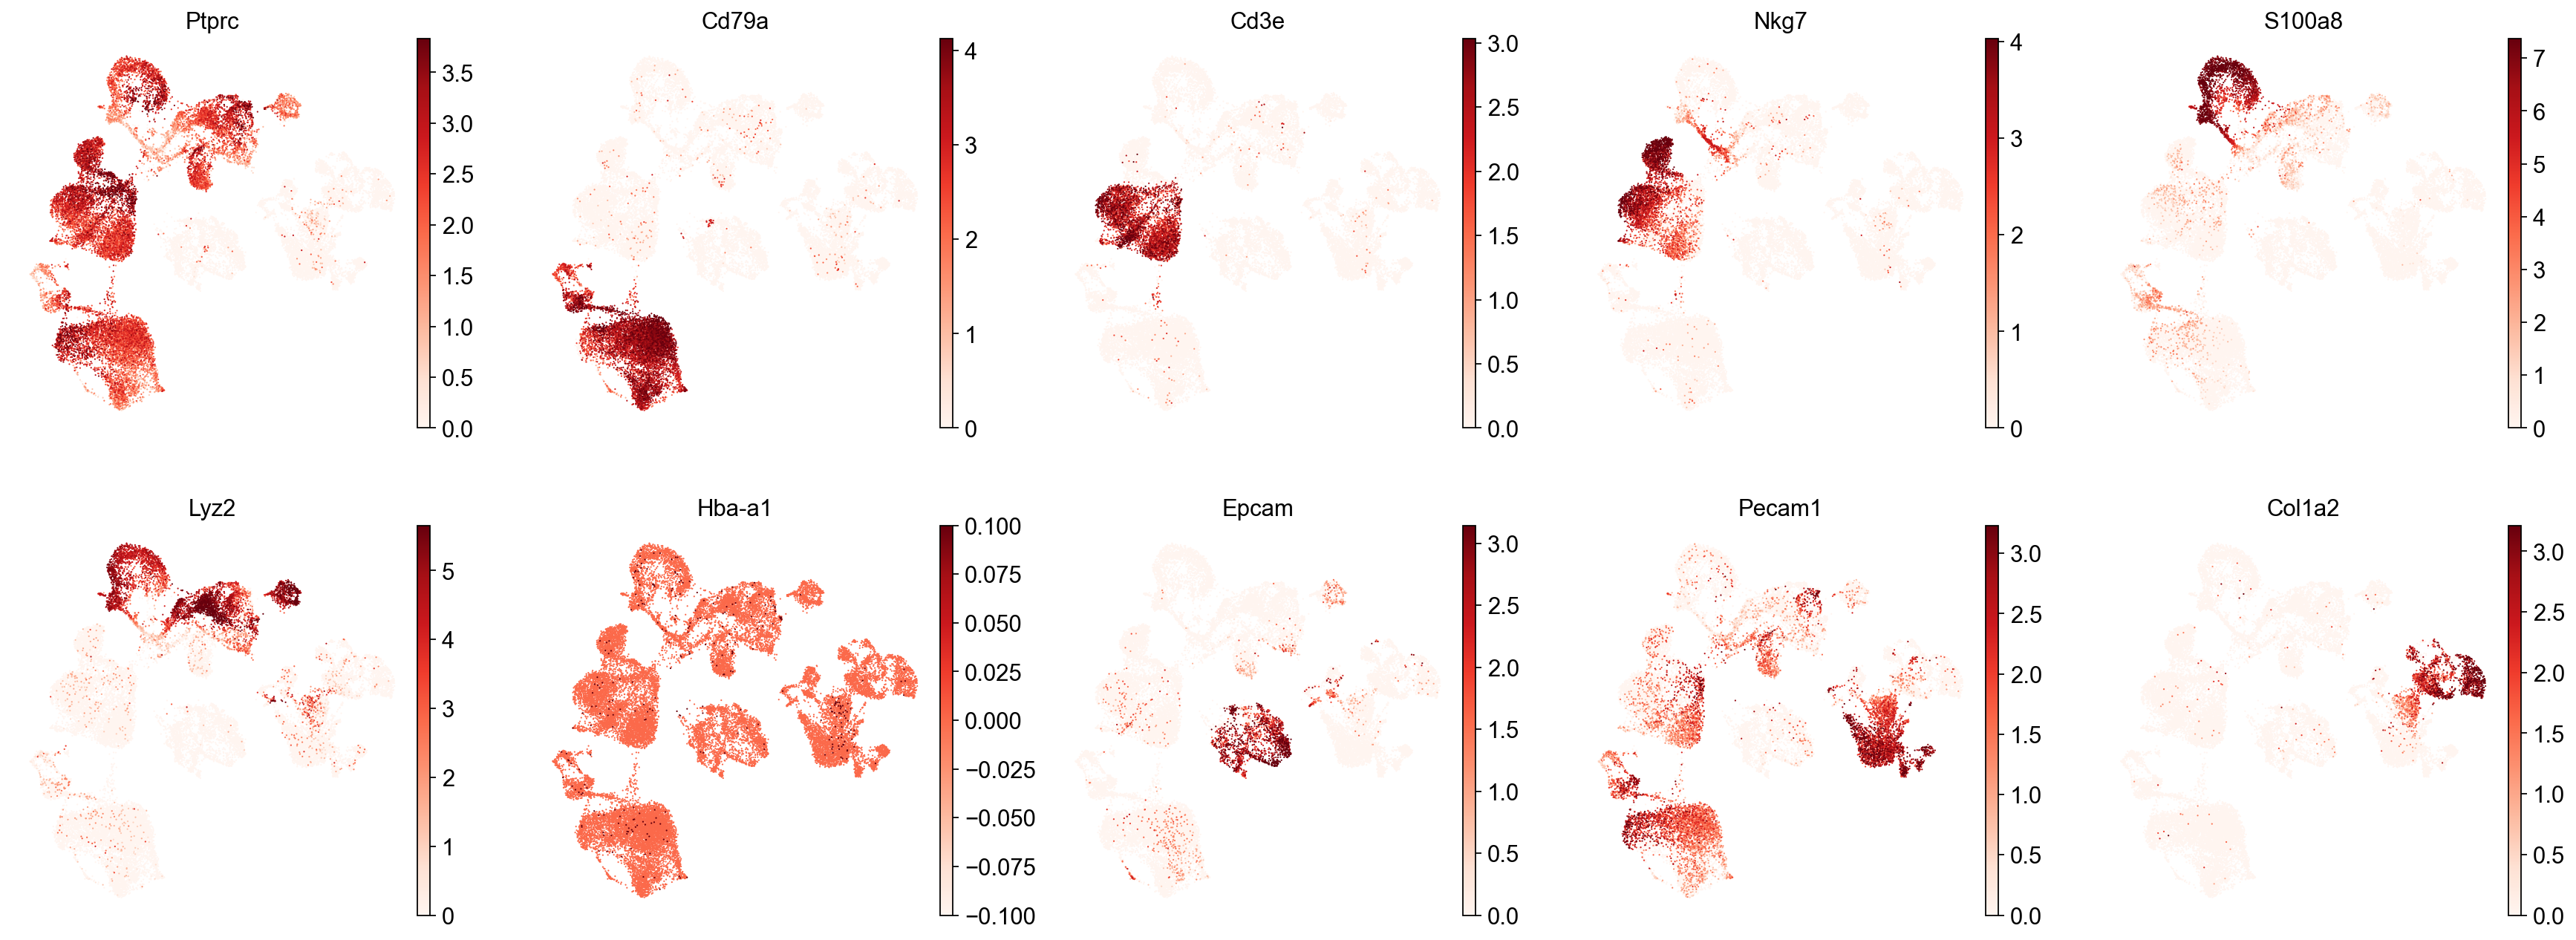

X_umap_harmony


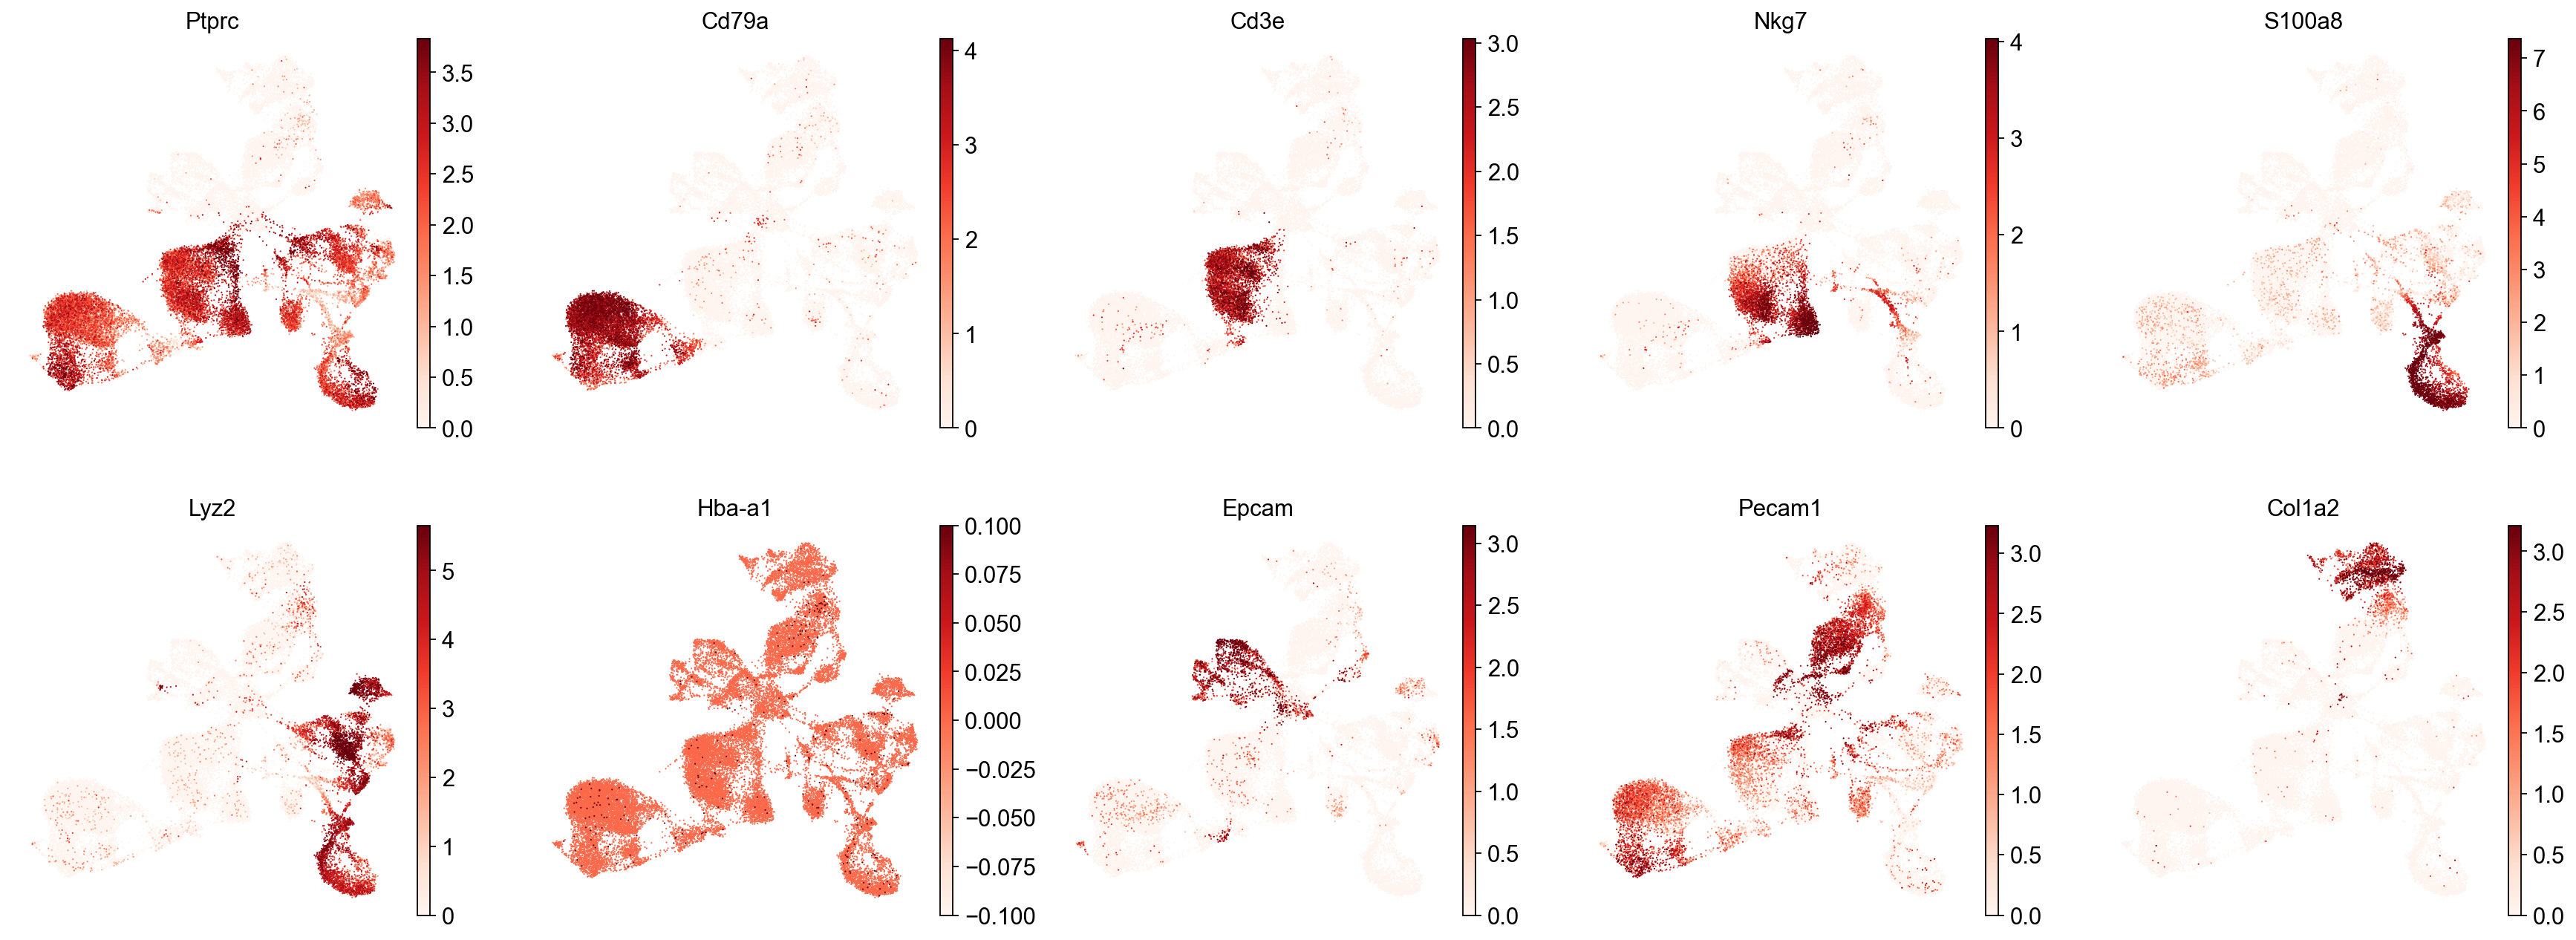

In [10]:
MARKERS = {
    "Immune (Ptprc)": "Ptprc", "B cell": "Cd79a", "T cell": "Cd3e", "NK": "Nkg7",
    "Neutrophil": "S100a8", "Monocyte/Macro": "Lyz2", "Erythroid": "Hba-a1",
    "Epithelial": "Epcam", "Endothelial": "Pecam1", "Fibroblast": "Col1a2",
}
genes = [g for g in MARKERS.values() if g in adata.raw.var_names]
for basis in ["X_umap_unintegrated", "X_umap_harmony"]:
    print(basis)
    sc.pl.embedding(adata, basis, color=genes, ncols=5, vmax="p99", cmap="Reds", use_raw=True)

In [11]:
sc.pp.neighbors(adata, use_rep="X_pca_harmony", n_neighbors=15, random_state=SEED)
adata.obsm["X_umap"] = adata.obsm["X_umap_harmony"].copy()

## 7. Clusters, markers and provisional labels

Leiden clustering on the integrated neighbour graph at three resolutions.
`0.5` is used below; finer resolutions are kept for sub-clustering.

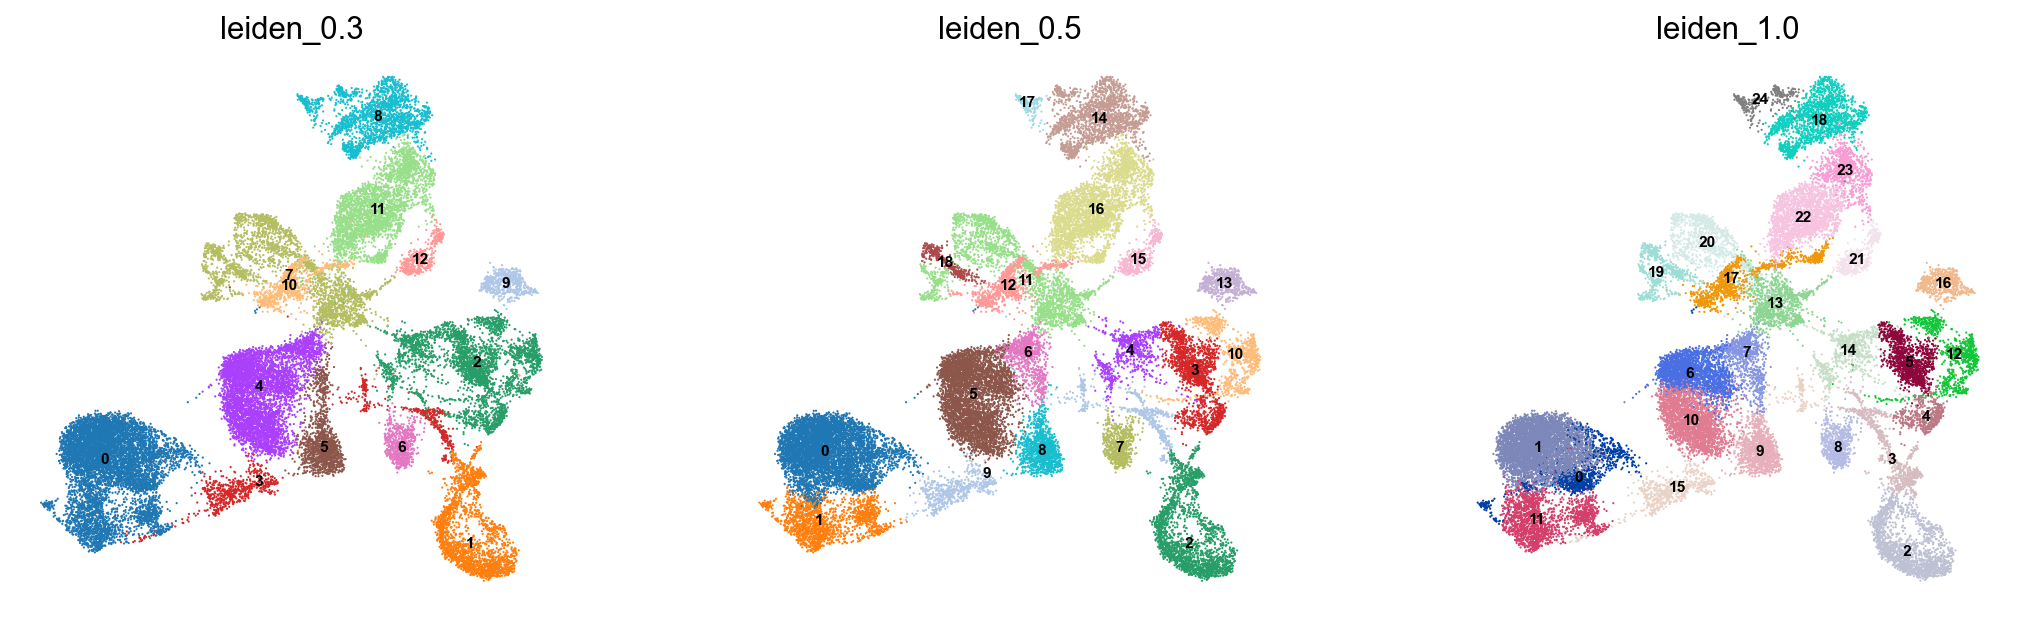

tissue share of each cluster


tissue,BoneMarrow,LargeI,lung,pbmc,spleen
leiden_0.5,,,,,
0,0.13,0.05,0.07,0.12,0.63
1,0.48,0.03,0.06,0.15,0.28
2,0.85,0.00,0.00,0.14,0.01
3,0.64,0.00,0.17,0.11,0.09
4,0.58,0.04,0.19,0.07,0.12
5,0.22,0.06,0.14,0.10,0.48
6,0.29,0.07,0.16,0.16,0.32
7,0.88,0.00,0.02,0.04,0.05
8,0.11,0.01,0.35,0.31,0.22


In [12]:
for res in [0.3, 0.5, 1.0]:
    sc.tl.leiden(adata, resolution=res, key_added=f"leiden_{res}", flavor="igraph", n_iterations=2,
                 random_state=SEED)
CLUSTER = "leiden_0.5"
sc.pl.umap(adata, color=["leiden_0.3", CLUSTER, "leiden_1.0"], legend_loc="on data", legend_fontsize=7, ncols=3)

ct = pd.crosstab(adata.obs[CLUSTER], adata.obs["tissue"], normalize="index").round(2)
print("tissue share of each cluster")
display(ct)

In [13]:
sc.tl.rank_genes_groups(adata, CLUSTER, method="wilcoxon", use_raw=True, pts=True)
top = sc.get.rank_genes_groups_df(adata, None)
top = top[(top["pvals_adj"] < 0.05) & (top["logfoldchanges"] > 1)]
top_genes = top.groupby("group", observed=True).head(8).groupby("group", observed=True)["names"].apply(", ".join)
display(top_genes.to_frame("top markers (Wilcoxon, log2FC > 1)"))
top.to_csv(OUT_DIR / f"markers_{CLUSTER}.csv", index=False)

,"top markers (Wilcoxon, log2FC > 1)"
group,
0,"Cd79a, Cd74, H2-Aa, H2-Eb1, Cd79b, Ly6d, H2-Ab..."
1,"Ebf1, Bach2, Foxp1, Aff3, Ighm, Pax5, Syk, Arh..."
10,"Cst3, Psap, Tmsb4x, H2-Aa, Atox1, Cd74, H2-Ab1..."
11,"mt-Co1, mt-Co2, mt-Cytb, mt-Atp6, mt-Nd4, mt-C..."
12,"Hsp90ab1, Eef1a1, Hspa8, Actg1, Ptma, Ybx1, Ep..."
13,"Ctsd, Ftl1, Ccl6, Chil3, Cd9, Fth1, Plet1, Lyz2"
14,"Gsn, Bgn, Serping1, Sparc, Ltbp4, Igfbp7, Mgp,..."
15,"Prdx6, Ager, Hopx, Emp2, Cldn18, Sparc, Sec14l..."
16,"Epas1, Adgrf5, Clic4, Ramp2, Cdh5, Egfl7, Ly6c..."


### Provisional broad labels

Each cluster is labelled with the broad type whose marker set has the highest
mean score. This is a **starting point, not an annotation**: check every
label against the marker table above and the dot plot, split mixed clusters,
and rename. Tissue-resident types (alveolar macrophages, goblet cells,
AT2 cells...) need finer, tissue-specific markers.

,label,score margin over 2nd,n_cells
leiden_0.5,,,
0,B cell,1.27,5955
1,B cell,0.97,1717
10,Dendritic,0.12,871
7,Dendritic,0.30,712
16,Endothelial,1.22,3012
12,Endothelial,0.02,798
15,Epithelial,0.70,444
11,Epithelial,1.01,2211
18,Epithelial,0.98,326


Low margins (< ~0.2) mark clusters to check by hand.


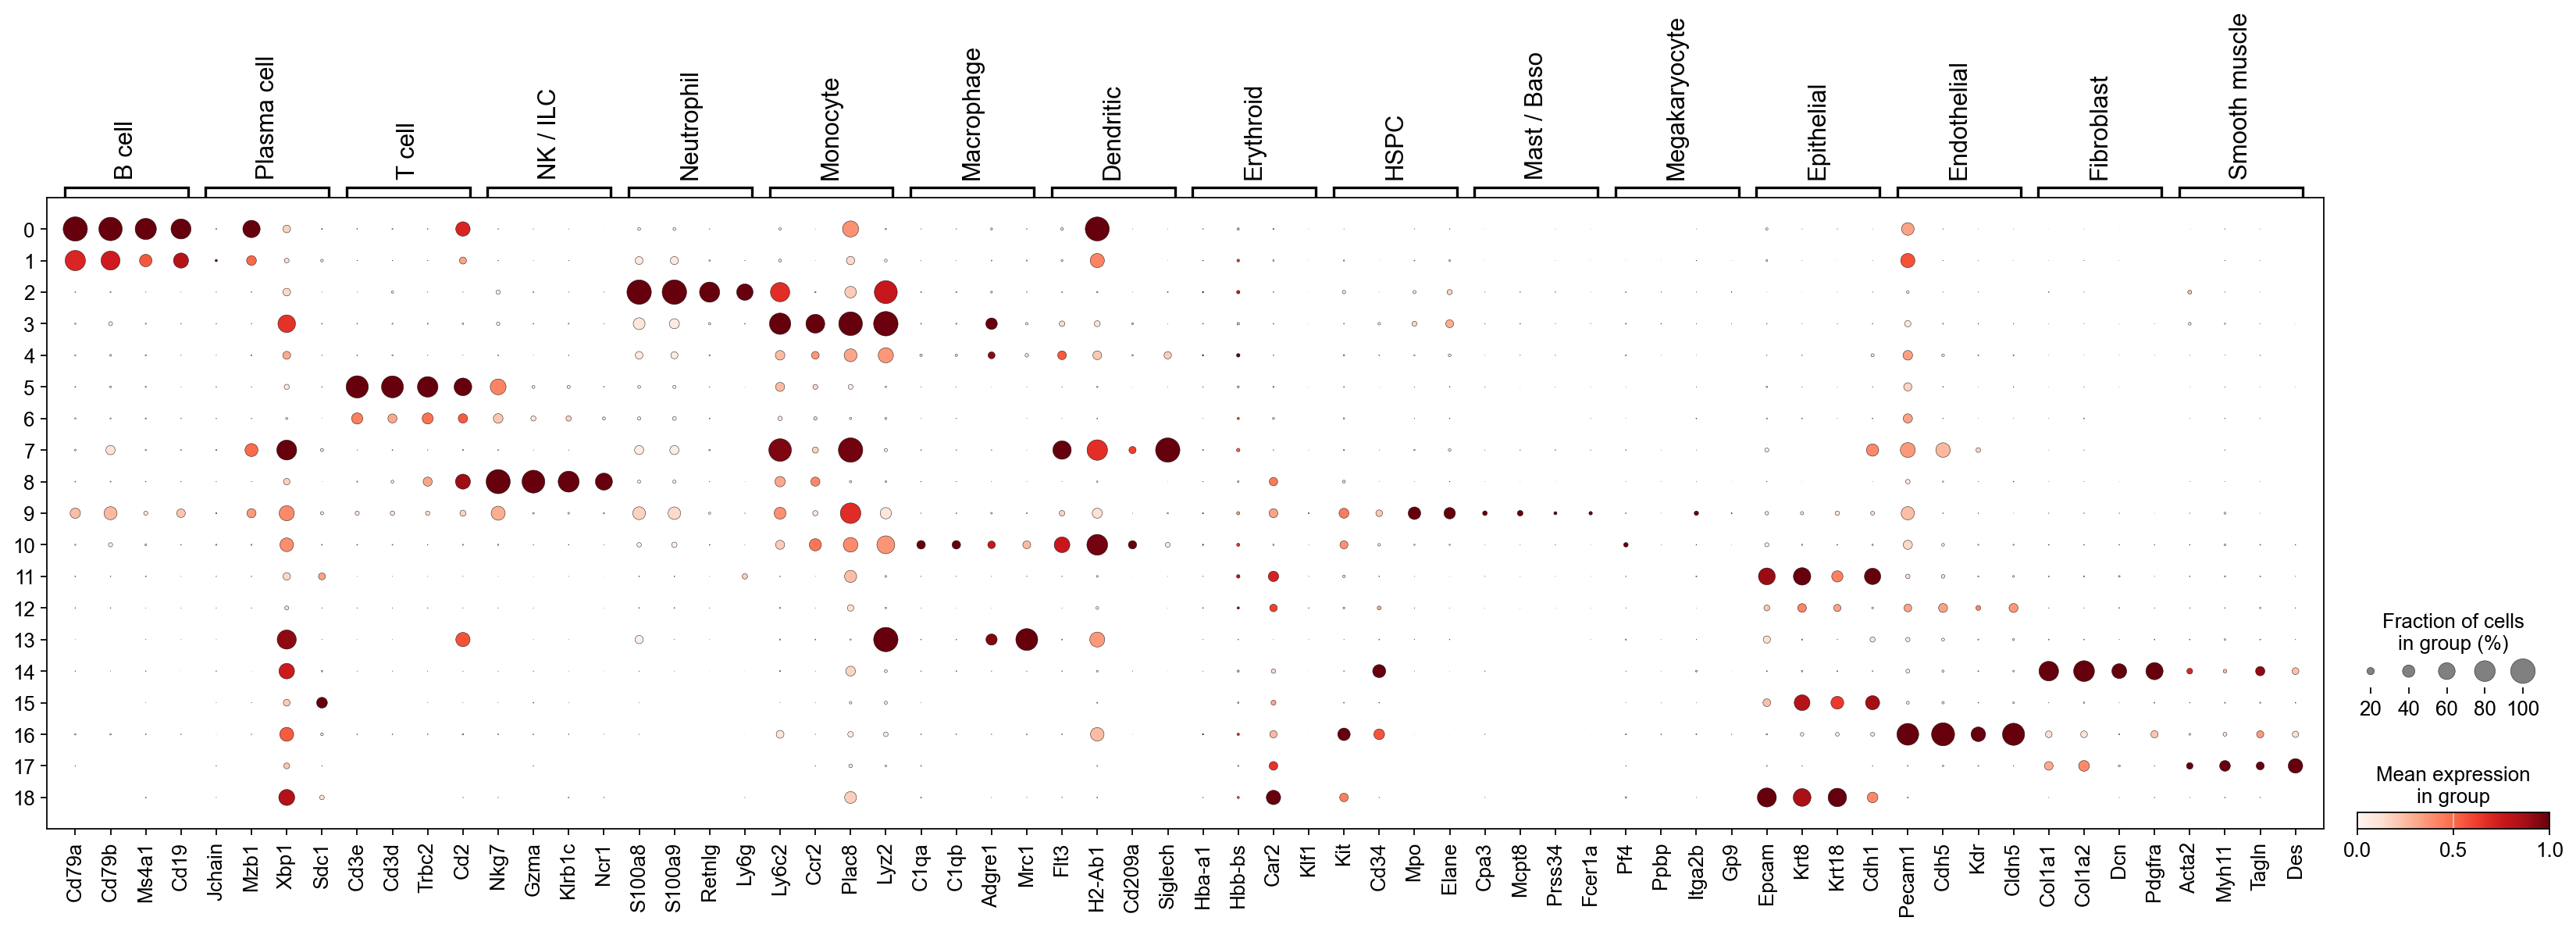

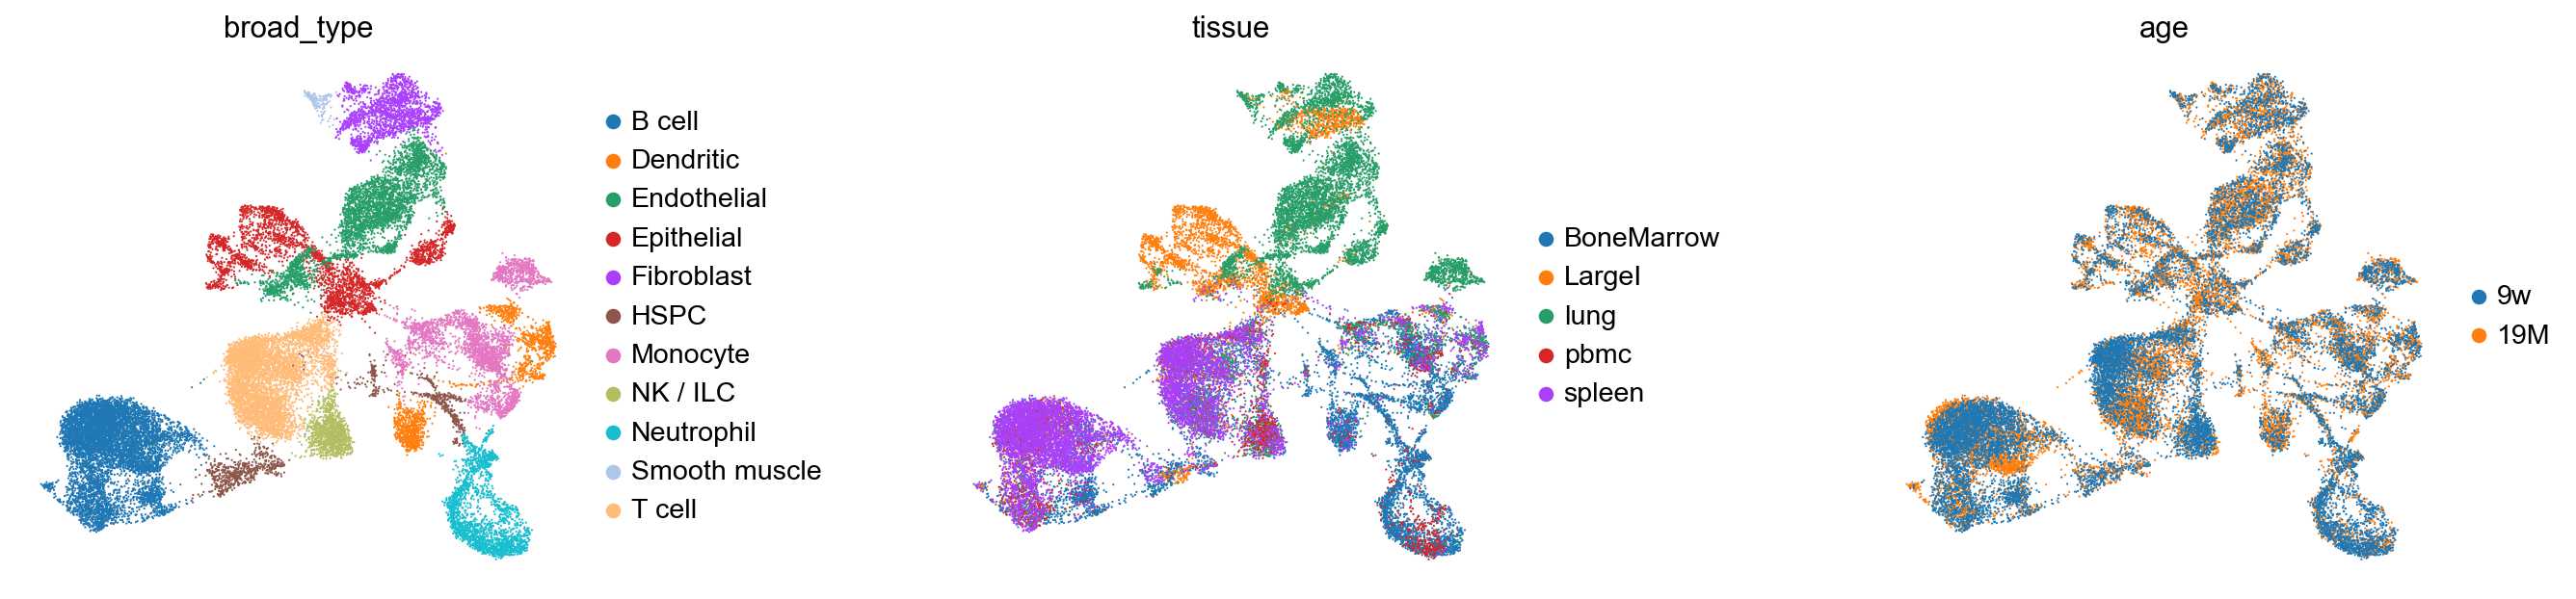

In [14]:
BROAD = {
    "B cell":        ["Cd79a", "Cd79b", "Ms4a1", "Cd19"],
    "Plasma cell":   ["Jchain", "Mzb1", "Xbp1", "Sdc1"],
    "T cell":        ["Cd3e", "Cd3d", "Trbc2", "Cd2"],
    "NK / ILC":      ["Nkg7", "Gzma", "Klrb1c", "Ncr1"],
    "Neutrophil":    ["S100a8", "S100a9", "Retnlg", "Ly6g"],
    "Monocyte":      ["Ly6c2", "Ccr2", "Plac8", "Lyz2"],
    "Macrophage":    ["C1qa", "C1qb", "Adgre1", "Mrc1"],
    "Dendritic":     ["Flt3", "H2-Ab1", "Cd209a", "Siglech"],
    "Erythroid":     ["Hba-a1", "Hbb-bs", "Car2", "Klf1"],
    "HSPC":          ["Kit", "Cd34", "Mpo", "Elane"],
    "Mast / Baso":   ["Cpa3", "Mcpt8", "Prss34", "Fcer1a"],
    "Megakaryocyte": ["Pf4", "Ppbp", "Itga2b", "Gp9"],
    "Epithelial":    ["Epcam", "Krt8", "Krt18", "Cdh1"],
    "Endothelial":   ["Pecam1", "Cdh5", "Kdr", "Cldn5"],
    "Fibroblast":    ["Col1a1", "Col1a2", "Dcn", "Pdgfra"],
    "Smooth muscle": ["Acta2", "Myh11", "Tagln", "Des"],
}
BROAD = {k: [g for g in v if g in adata.raw.var_names] for k, v in BROAD.items()}
BROAD = {k: v for k, v in BROAD.items() if v}
for k, v in BROAD.items():
    sc.tl.score_genes(adata, v, score_name=f"score_{k}", use_raw=True, random_state=SEED)
score_cols = [f"score_{k}" for k in BROAD]
cl_scores = adata.obs.groupby(CLUSTER, observed=True)[score_cols].mean()
cl_scores.columns = list(BROAD)
label = cl_scores.idxmax(1)
margin = cl_scores.apply(lambda r: r.nlargest(2).diff().abs().iloc[-1], axis=1)
adata.obs["broad_type"] = adata.obs[CLUSTER].map(label).astype("category")
display(pd.DataFrame({"label": label, "score margin over 2nd": margin.round(2),
                      "n_cells": adata.obs[CLUSTER].value_counts()}).sort_values("label"))
print("Low margins (< ~0.2) mark clusters to check by hand.")

sc.pl.dotplot(adata, BROAD, groupby=CLUSTER, standard_scale="var", use_raw=True)
sc.pl.umap(adata, color=["broad_type", "tissue", "age"], ncols=3, wspace=0.5)

## 8. Composition by tissue and age

Share of each broad type per **sample** (= per mouse and tissue), so each
point is one animal. With 2–3 mice per group these plots show direction and
spread; a formal test needs a compositional method (e.g. `scCODA`, `propeller`)
and should be read cautiously at this sample size.

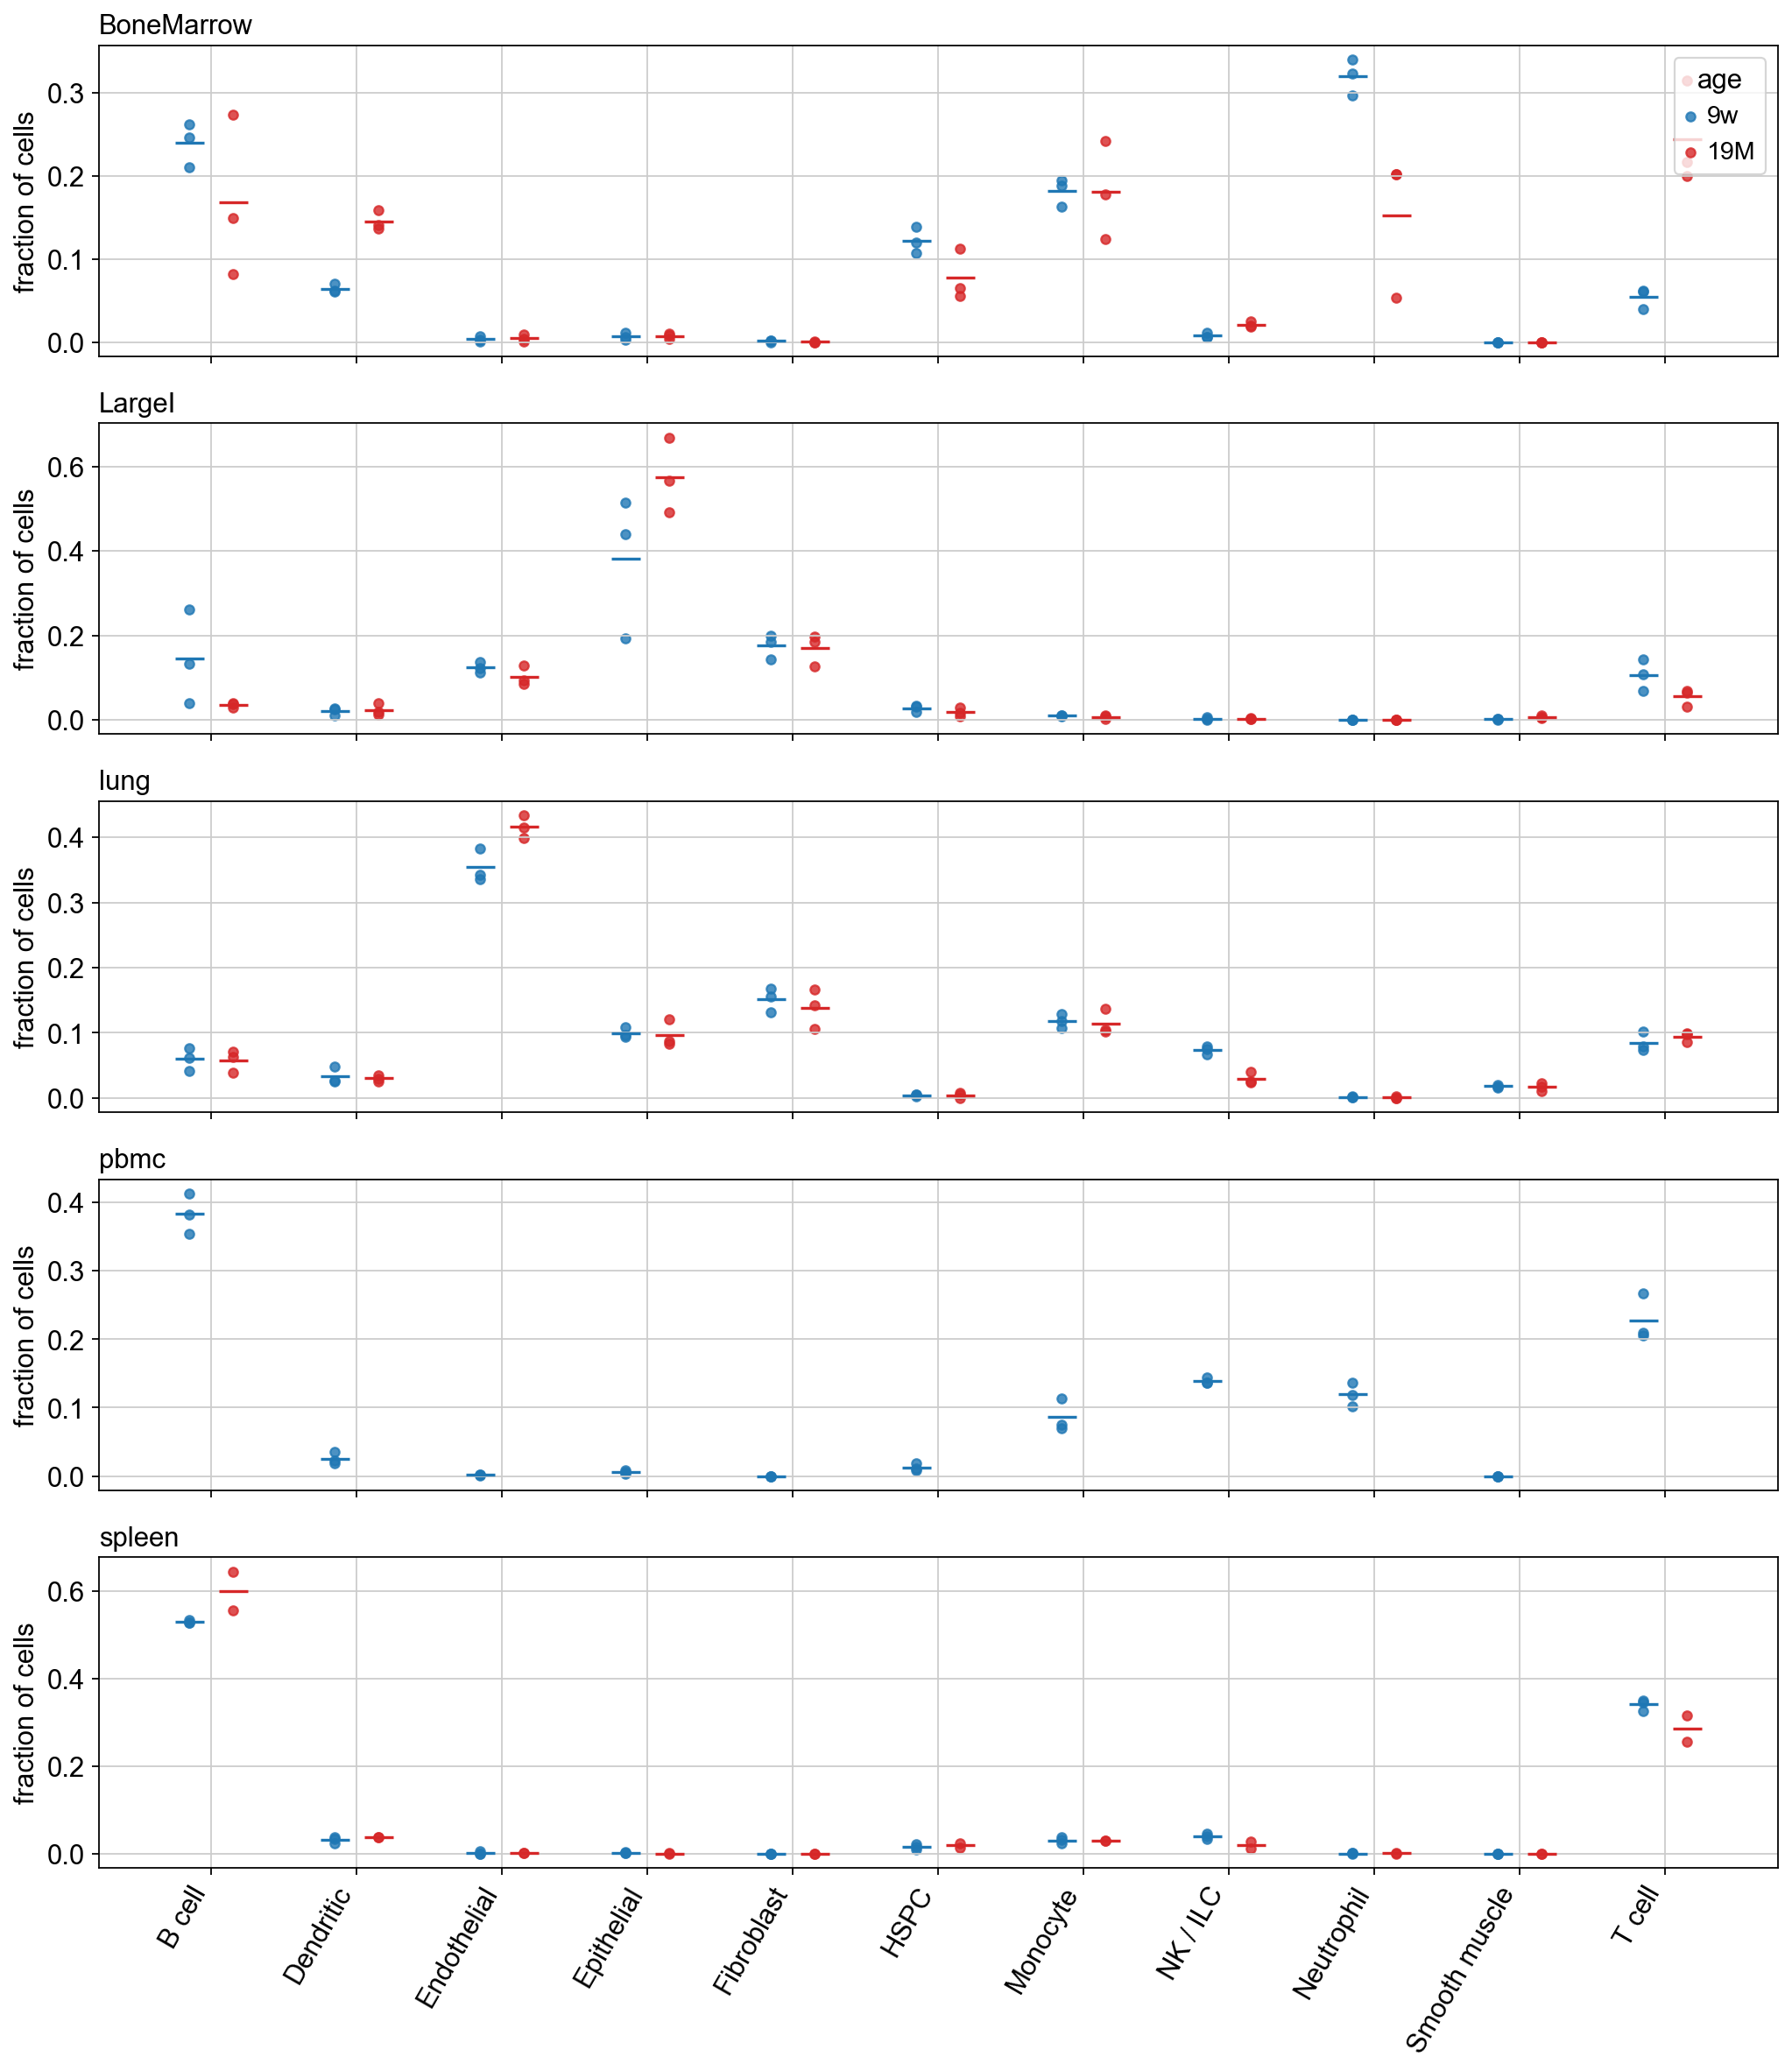

In [15]:
comp = pd.crosstab(adata.obs["sample"].astype(str), adata.obs["broad_type"].astype(str), normalize="index")
comp.columns.name = None
comp = comp.join(meta.set_index("sample")[["tissue", "age"]].astype(str))
long = comp.melt(id_vars=["tissue", "age"], ignore_index=False, var_name="broad_type", value_name="fraction")
long = long.reset_index(names="sample")
comp.to_csv(OUT_DIR / "composition_by_sample.csv")

tissues = sorted(long["tissue"].unique())
fig, axes = plt.subplots(len(tissues), 1, figsize=(13, 3 * len(tissues)), sharex=True, squeeze=False)
axes = axes[:, 0]
types = sorted(adata.obs["broad_type"].astype(str).unique())
for ax, t in zip(axes, tissues):
    d = long[long["tissue"] == t]
    for j, (age, col, off) in enumerate([("9w", "tab:blue", -0.15), ("19M", "tab:red", 0.15)]):
        dd = d[d["age"] == age]
        x = dd["broad_type"].map({k: i for i, k in enumerate(types)}) + off
        ax.scatter(x, dd["fraction"], color=col, s=22, label=age, alpha=0.8)
        means = dd.groupby("broad_type")["fraction"].mean().reindex(types)
        ax.hlines(means, np.arange(len(types)) + off - 0.1, np.arange(len(types)) + off + 0.1, color=col)
    ax.set_title(t, loc="left"); ax.set_ylabel("fraction of cells")
axes[0].legend(title="age", loc="upper right")
axes[-1].set_xticks(range(len(types))); axes[-1].set_xticklabels(types, rotation=60, ha="right")
plt.tight_layout(); plt.show()

## 9. Old vs young: pseudobulk differential expression

For every tissue × broad type with at least 2 old and 2 young mice having
≥ 20 cells each, raw counts are **summed per mouse** and tested with
DESeq2 (`pydeseq2`), design `~ age`. This uses the uncorrected counts, so
sample-level correction from the integration cannot erase the age effect —
but neither can it remove a batch effect, because here sample and mouse are
the same thing. Read the hit lists as candidates.

PBMC old samples (A170, A172) differ in depth and cell number from the young
ones; a PBMC age effect may partly be a technical one.

In [16]:
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats
from pydeseq2.default_inference import DefaultInference

MIN_CELLS = 20
inference = DefaultInference(n_cpus=4)
results = {}
for (t, b), idx in adata.obs.groupby(["tissue", "broad_type"], observed=True).groups.items():
    sub = adata[idx]
    n = sub.obs["sample"].value_counts()
    keep = n[n >= MIN_CELLS].index
    sub = sub[sub.obs["sample"].isin(keep)]
    ages = sub.obs.drop_duplicates("sample")["age"].value_counts()
    if ages.get("9w", 0) < 2 or ages.get("19M", 0) < 2:
        continue
    pb = pd.DataFrame(
        {s: np.asarray(sub[sub.obs["sample"] == s].layers["counts"].sum(0)).ravel() for s in keep},
        index=sub.var_names).T
    pb = pb.loc[:, (pb >= 10).sum(0) >= 2]
    md_ = meta.set_index("sample").loc[pb.index, ["age"]].astype(str)
    dds = DeseqDataSet(counts=pb.astype(int), metadata=md_, design="~age",
                       inference=inference, quiet=True)
    dds.deseq2()
    st = DeseqStats(dds, contrast=["age", "19M", "9w"], inference=inference, quiet=True)
    st.summary()
    r = st.results_df.sort_values("padj")
    results[(t, b)] = r
    r.to_csv(OUT_DIR / f"pseudobulk_DE_{t}_{b.replace(' / ', '_').replace(' ', '_')}.csv")

summary = pd.DataFrame([{"tissue": t, "broad_type": b, "n_genes": len(r),
                         "padj<0.05": int((r["padj"] < 0.05).sum()),
                         "up in old": int(((r["padj"] < 0.05) & (r["log2FoldChange"] > 0)).sum()),
                         "top genes": ", ".join(r.index[:6])}
                        for (t, b), r in results.items()])
display(summary.sort_values(["tissue", "padj<0.05"], ascending=[True, False]))

,tissue,broad_type,n_genes,padj<0.05,up in old,top genes
0,BoneMarrow,B cell,9140,582,415,"Fcer1g, Atxn1, AC133103.1, Ahnak, Ly6a, C13002..."
3,BoneMarrow,Monocyte,10233,237,92,"Hist1h2ap, F630028O10Rik, Nfkbiz, Col19a1, Rps..."
5,BoneMarrow,T cell,8467,235,112,"Lef1, Dapl1, Aff3, S100a6, Satb1, Tyrobp"
4,BoneMarrow,Neutrophil,8617,178,138,"Cxcl2, H2-Aa, Bst2, H2-Ab1, Fosb, Ier3"
1,BoneMarrow,Dendritic,9701,88,11,"Hmox1, Fcna, Vcam1, Lpl, Apoe, Rps28"
2,BoneMarrow,HSPC,10589,62,34,"Col19a1, Camp, Jun, Fosb, Fos, Ier3"
10,LargeI,T cell,3551,183,164,"Dusp1, Tnfaip3, Nr4a1, Gadd45b, Ern1, Fosb"
8,LargeI,Epithelial,10932,42,21,"Gm47350, Slc24a1, Gadd45g, Hes7, Ccdc60, Mt1"
9,LargeI,Fibroblast,7384,13,11,"Pde10a, Rpl21, C4b, Igfbp5, Mt2, Med12l"
7,LargeI,Endothelial,3590,6,6,"Lars2, Peak1, Gvin1, Clu, Mecom, Mctp1"


## 10. Save

In [17]:
for c in adata.obs.columns:
    if adata.obs[c].dtype == object:
        adata.obs[c] = adata.obs[c].astype("category")
adata.write_h5ad(OUT_DIR / "integrated.h5ad", compression="gzip")
print("wrote", OUT_DIR / "integrated.h5ad", adata)

wrote results/all_tissues/integrated.h5ad AnnData object with n_obs × n_vars = 30966 × 21937
    obs: 'sample', 'tissue', 'age', 'sex', 'mouse', 'tissue_age', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'qc_fail', 'doublet_score', 'predicted_doublet', 'leiden_0.3', 'leiden_0.5', 'leiden_1.0', 'score_B cell', 'score_Plasma cell', 'score_T cell', 'score_NK / ILC', 'score_Neutrophil', 'score_Monocyte', 'score_Macrophage', 'score_Dendritic', 'score_Erythroid', 'score_HSPC', 'score_Mast / Baso', 'score_Megakaryocyte', 'score_Epithelial', 'score_Endothelial', 'score_Fibroblast', 'score_Smooth muscle', 'broad_type'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts'

## Next steps

* Fix the provisional labels by hand, then sub-cluster the big compartments
  (T cells, myeloid, epithelium) per tissue for finer types.
* Re-run section 9 with the refined labels.
* Shared mice across tissues (ids 1–3, 52–54) allow paired analyses, e.g.
  whether a mouse's age shift in bone marrow tracks its shift in blood.